# Credit Scoring - Modeling

## Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import shap
from sklearn import set_config
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier


Global settings used throughout the notebook: random state, cross-validation setup and the columns handled in preprocessing.

In [2]:
set_config(transform_output="pandas")
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
N_SPLITS = 5
TEST_SIZE = 0.20
TARGET = "SeriousDlqin2yrs"
XGB_EVAL_METRIC = "auc"

COLS_TO_CAP = [
    "RevolvingUtilizationOfUnsecuredLines",
    "MonthlyIncome",
    "DebtRatio",
    "IncomePerDependent",
]
NUMERIC_COLS = [
    "RevolvingUtilizationOfUnsecuredLines",
    "MonthlyIncome",
    "DebtRatio",
    "IncomePerDependent",
    "NumberOfDependents",
]

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

## Read data

In [3]:
df = pd.read_parquet("../data/processed.parquet")

X = df.drop(columns=[TARGET])
y = df[TARGET]

## Train/test split

The test set (20%) is held out until final evaluation. Model selection is based on 5-fold stratified cross-validation on the training set, where each fold serves once as the validation set.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
X_train = X_train.copy()
X_test = X_test.copy()

In [5]:
print("Train set target distribution:")
display(y_train.value_counts(normalize=True))
print("\nTest set target distribution:")
display(y_test.value_counts(normalize=True))

Train set target distribution:


SeriousDlqin2yrs
0    0.933158
1    0.066842
Name: proportion, dtype: float64


Test set target distribution:


SeriousDlqin2yrs
0    0.933167
1    0.066833
Name: proportion, dtype: float64

The share of defaults is the same in both sets (6.68%), confirming that the stratified split preserved the class proportions.

## Preprocessing

Capping and imputation are done inside the pipeline, so they are fitted only on the training data.

In [6]:
class CappingTransformer(BaseEstimator, TransformerMixin):
    """Caps selected columns at a percentile learned from the training data."""

    def __init__(self, cols, percentile=0.99):
        self.cols = cols
        self.percentile = percentile

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns)
        self.caps_ = {}
        for c in self.cols:
            self.caps_[c] = X[c].quantile(self.percentile)
        return self

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_

    def transform(self, X):
        X = X.copy()
        for c in self.cols:
            X[c] = X[c].clip(upper=self.caps_[c])
        return X

In [7]:
numeric_transformer = Pipeline(
    steps=[
        ("capping", CappingTransformer(cols=COLS_TO_CAP)),
        ("imputer", SimpleImputer(strategy="median")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[("num_preprocessing", numeric_transformer, NUMERIC_COLS)],
    remainder="passthrough",
    verbose_feature_names_out=False,
)

In [8]:
def evaluate_cv(name, pipeline, X, y, cv):
    """Run cross-validation and return train and validation AUC."""
    scores = cross_validate(
        pipeline, X, y, cv=cv, scoring="roc_auc", return_train_score=True
    )
    train_auc = scores["train_score"].mean()
    cv_auc = scores["test_score"].mean()
    cv_std = scores["test_score"].std()

    print(
        f"{name}\nTrain AUC: {train_auc:.4f} | CV AUC: {cv_auc:.4f} (+/- {cv_std:.4f})  |  Gini: {2 * cv_auc - 1:.4f}"
    )
    print(f"CV AUC per fold: {scores['test_score'].round(4)}\n")

    return {
        "Model": name,
        "Train AUC": round(train_auc, 4),
        "CV AUC": round(cv_auc, 4),
        "Std": round(cv_std, 4),
        "Gini": round(2 * cv_auc - 1, 3),
    }

## Logistic regression pipeline

Logistic regression is used as a baseline.

- Features are scaled with `StandardScaler`, because logistic regression is sensitive to the scale of the features.
- Default L2 regularization is used (C = 1.0).
- `class_weight="balanced"` gives more weight to defaults to handle the class imbalance.

In [9]:
model_results = []

logistic_regression_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("scaler", StandardScaler()),
        (
            "model",
            LogisticRegression(
                max_iter=1000, random_state=RANDOM_STATE, class_weight="balanced"
            ),
        ),
    ]
)

model_results.append(
    evaluate_cv(
        "Logistic Regression (baseline)",
        logistic_regression_pipeline,
        X_train,
        y_train,
        cv,
    )
)

Logistic Regression (baseline)
Train AUC: 0.8574 | CV AUC: 0.8572 (+/- 0.0065)  |  Gini: 0.7143
CV AUC per fold: [0.8553 0.8466 0.8646 0.8559 0.8636]



Mean AUC of 0.857 with low variation across folds (0.0065) provides a solid reference point for more complex models.

## XGBoost pipeline

XGBoost is the main model. Three configurations are compared:

- default parameters, as a starting point,
- manually chosen parameters,
- parameters tuned with Optuna.

Feature scaling is not needed for tree-based models.

`scale_pos_weight` gives more weight to defaults during training. It is set to the ratio of non-defaults to defaults in the training set.

In [10]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight: {scale_pos_weight:.2f}")

scale_pos_weight: 13.96


### Default parameters

In [11]:
xgb_pipeline_default = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        (
            "model",
            XGBClassifier(
                scale_pos_weight=scale_pos_weight,
                random_state=RANDOM_STATE,
                eval_metric=XGB_EVAL_METRIC,
            ),
        ),
    ]
)

model_results.append(
    evaluate_cv(
        "XGBoost (default parameters)", xgb_pipeline_default, X_train, y_train, cv
    )
)


XGBoost (default parameters)
Train AUC: 0.9411 | CV AUC: 0.8420 (+/- 0.0063)  |  Gini: 0.6841
CV AUC per fold: [0.8375 0.8333 0.8485 0.841  0.8499]



XGBoost with default parameters performs worse than the logistic regression baseline (CV AUC 0.842 vs 0.857). The large gap between training AUC (0.941) and validation AUC shows that the model overfits.

### Manual parameters

The parameters are chosen to reduce the overfitting seen with the default configuration:

- shallower trees (`max_depth` = 3 instead of 6),
- lower learning rate (0.05 instead of 0.3), with more trees (300) to compensate,
- random sampling of rows and columns for each tree (`subsample` and `colsample_bytree` = 0.8).

In [12]:
manual_params = {
    "n_estimators": 300,
    "max_depth": 3,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 1,
}

xgb_pipeline_manual = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        (
            "model",
            XGBClassifier(
                **manual_params,
                random_state=RANDOM_STATE,
                eval_metric=XGB_EVAL_METRIC,
                scale_pos_weight=scale_pos_weight,
            ),
        ),
    ]
)

model_results.append(
    evaluate_cv(
        "XGBoost (manual parameters)", xgb_pipeline_manual, X_train, y_train, cv
    )
)

XGBoost (manual parameters)
Train AUC: 0.8750 | CV AUC: 0.8647 (+/- 0.0060)  |  Gini: 0.7294
CV AUC per fold: [0.8629 0.8549 0.8698 0.8637 0.8721]



This configuration improves CV AUC to 0.865, better than the baseline. The gap between training and validation AUC dropped to about 0.01, so the overfitting is largely removed.

### Optuna tuning

Parameters are tuned with Optuna, which searches for the combination that maximizes CV AUC on the training set. The search runs for 30 trials within the following ranges:

- `max_depth`: 3–8
- `learning_rate`: 0.01–0.15
- `n_estimators`: 100–600
- `subsample` and `colsample_bytree`: 0.6–1.0
- `min_child_weight`: 1–10

In [13]:
def objective(trial):
    max_depth = trial.suggest_int("max_depth", 3, 8)
    learning_rate = trial.suggest_float("learning_rate", 0.01, 0.15, log=True)
    n_estimators = trial.suggest_int("n_estimators", 100, 600)
    subsample = trial.suggest_float("subsample", 0.6, 1.0)
    colsample_bytree = trial.suggest_float("colsample_bytree", 0.6, 1.0)
    min_child_weight = trial.suggest_int("min_child_weight", 1, 10)

    xgb_pipeline = Pipeline(
        steps=[
            ("preprocessing", preprocessor),
            (
                "model",
                XGBClassifier(
                    n_estimators=n_estimators,
                    max_depth=max_depth,
                    learning_rate=learning_rate,
                    scale_pos_weight=scale_pos_weight,
                    subsample=subsample,
                    colsample_bytree=colsample_bytree,
                    min_child_weight=min_child_weight,
                    random_state=RANDOM_STATE,
                    eval_metric=XGB_EVAL_METRIC,
                ),
            ),
        ]
    )

    scores = cross_val_score(xgb_pipeline, X_train, y_train, cv=cv, scoring="roc_auc")

    return scores.mean()


study = optuna.create_study(
    direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
)
study.optimize(objective, n_trials=30)

In [14]:
xgb_pipeline_best = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        (
            "model",
            XGBClassifier(
                **study.best_params,
                scale_pos_weight=scale_pos_weight,
                random_state=RANDOM_STATE,
                eval_metric=XGB_EVAL_METRIC,
            ),
        ),
    ]
)

model_results.append(
    evaluate_cv(
        "XGBoost (optuna-tuned parameters)", xgb_pipeline_best, X_train, y_train, cv
    )
)

XGBoost (optuna-tuned parameters)
Train AUC: 0.8758 | CV AUC: 0.8650 (+/- 0.0057)  |  Gini: 0.7300
CV AUC per fold: [0.8635 0.8559 0.8701 0.8637 0.8719]



In [15]:
study.best_params

{'max_depth': 4,
 'learning_rate': 0.018762335050031005,
 'n_estimators': 424,
 'subsample': 0.6263373787242437,
 'colsample_bytree': 0.6318646596907883,
 'min_child_weight': 9}

The best configuration also uses shallow trees and a low learning rate, similar to the manual choice. CV AUC improves only marginally, from 0.8647 to 0.8650, so tuning brings practically no gain over the manual configuration. Optuna is not better in every fold, which confirms that the difference is negligible.

### Parameters comparison

In [16]:
default_params = {
    "n_estimators": 100,
    "max_depth": 6,
    "learning_rate": 0.3,
    "subsample": 1.0,
    "colsample_bytree": 1.0,
    "min_child_weight": 1,
}

params_comparison = pd.DataFrame(
    {
        "Default": default_params,
        "Manual": manual_params,
        "Optuna": study.best_params,
    }
).round(3)

params_comparison

,Default,Manual,Optuna
n_estimators,100.0,300.00,424.000
max_depth,6.0,3.00,4.000
learning_rate,0.3,0.05,0.019
subsample,1.0,0.80,0.626
colsample_bytree,1.0,0.80,0.632
min_child_weight,1.0,1.00,9.000


Unlike the default setup, both the manual and Optuna configurations use shallow trees and a low learning rate. The differences between them are small and give almost the same AUC.

## Models comparison

In [17]:
model_results_df = pd.DataFrame(model_results)

model_results_df

,Model,Train AUC,CV AUC,Std,Gini
0,Logistic Regression (baseline),0.8574,0.8572,0.0065,0.714
1,XGBoost (default parameters),0.9411,0.8420,0.0063,0.684
2,XGBoost (manual parameters),0.8750,0.8647,0.0060,0.729
3,XGBoost (optuna-tuned parameters),0.8758,0.8650,0.0057,0.730


- Logistic regression does not overfit; its lower performance is likely due to the linear decision boundary.

- XGBoost with default parameters overfits, while the manual and Optuna configurations give the best validation results with only a small gap between training and validation AUC.

- The improvement of the best XGBoost over logistic regression is modest (CV AUC 0.865 vs 0.857), but consistent: XGBoost is better in every fold.

- The Optuna-tuned XGBoost is selected as the final model and evaluated on the test set.

## Evaluation on test set

The final model is trained on the full training set and evaluated once on the held-out test set.

In [18]:
xgb_pipeline_best.fit(X_train, y_train)

y_proba = xgb_pipeline_best.predict_proba(X_test)[:, 1]

auc_test = roc_auc_score(y_test, y_proba)

gini_test = 2 * auc_test - 1

print(f"Test AUC: {auc_test:.4f}")
print(f"Test Gini: {gini_test:.4f}")

Test AUC: 0.8699
Test Gini: 0.7397


- Test AUC is 0.870 (Gini 0.740), close to the cross-validated AUC of 0.865. This indicates that the model generalizes well to unseen data and that the validation results were reliable.

- The slightly higher test result is within the variation observed between folds.

### ROC curves

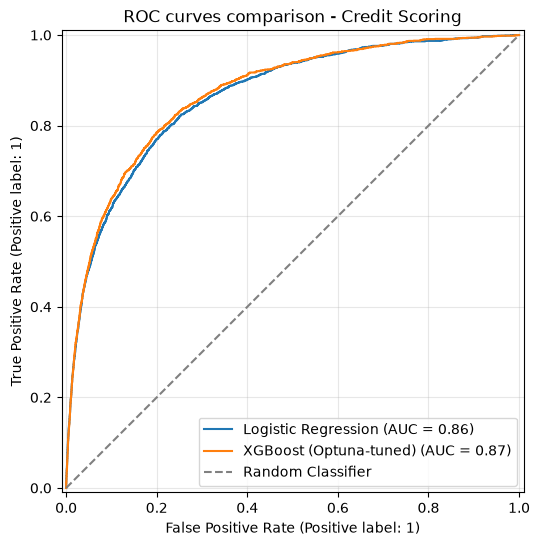

In [19]:
logistic_regression_pipeline.fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_estimator(
    logistic_regression_pipeline, X_test, y_test, name="Logistic Regression", ax=ax
)

RocCurveDisplay.from_estimator(
    xgb_pipeline_best, X_test, y_test, name="XGBoost (Optuna-tuned)", ax=ax
)

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Classifier")

ax.set_title("ROC curves comparison - Credit Scoring")
ax.grid(alpha=0.3)
plt.legend()
plt.show()

The two curves are very close. XGBoost is slightly above logistic regression in part of the range. Both models are far from the random classifier.

### Threshold analysis

The threshold is selected on the training set (out-of-fold predictions) and then applied to the test set below.

In [20]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

y_proba_oof = cross_val_predict(
    xgb_pipeline_best, X_train, y_train, method="predict_proba", cv=cv
)[:, 1]

results = []
for t in thresholds:
    y_pred = (y_proba_oof >= t).astype(int)

    precision = precision_score(y_train, y_pred)
    recall = recall_score(y_train, y_pred)
    rejected_share = y_pred.mean()
    f1 = f1_score(y_train, y_pred)

    results.append(
        {
            "Threshold": t,
            "Precision": precision,
            "Recall": recall,
            "Rejected share": rejected_share,
            "F1 score": f1,
        }
    )

threshold_results_df = pd.DataFrame(results)

In [21]:
threshold_results_df.round(3)


,Threshold,Precision,Recall,Rejected share,F1 score
0,0.1,0.084,0.984,0.786,0.154
1,0.2,0.118,0.939,0.533,0.209
2,0.3,0.145,0.894,0.411,0.250
3,0.4,0.175,0.842,0.322,0.289
4,0.5,0.214,0.773,0.242,0.335
5,0.6,0.270,0.682,0.169,0.387
6,0.7,0.338,0.591,0.117,0.430
7,0.8,0.416,0.473,0.076,0.443
8,0.9,0.546,0.274,0.034,0.365


The threshold is chosen on out-of-fold predictions from the training set. Among the tested thresholds (step 0.1), the highest F1 score is at 0.8, with a very similar value at 0.7. The threshold is high because `scale_pos_weight` shifts the scores upwards.

### Classification report and confusion matrix

In [22]:
# threshold selected based on F1 score
THRESHOLD = 0.8

y_pred_test = (y_proba >= THRESHOLD).astype(int)

print(f"Classification report (threshold {THRESHOLD}):")
print(classification_report(y_test, y_pred_test))

Classification report (threshold 0.8):
              precision    recall  f1-score   support

           0       0.96      0.95      0.96     27995
           1       0.42      0.48      0.45      2005

    accuracy                           0.92     30000
   macro avg       0.69      0.72      0.70     30000
weighted avg       0.93      0.92      0.92     30000



In [23]:
print(f"Rejected share on test: {y_pred_test.mean():.1%}")

Rejected share on test: 7.5%


On the test set, the threshold of 0.8 gives similar results: precision 0.42 and recall 0.48 for defaults. Accuracy (0.92) is lower than 0.93, which we would get by predicting "no default" for everyone, so accuracy is not a useful metric here.

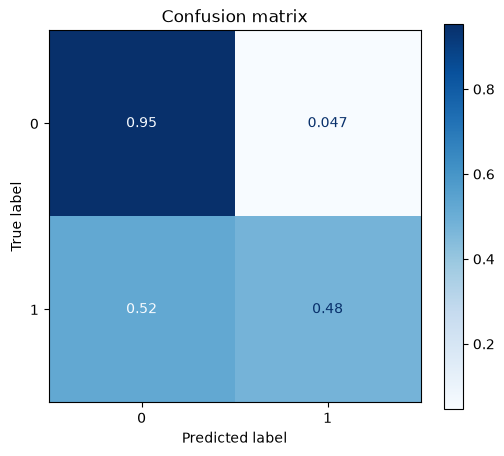

In [24]:
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test, cmap="Blues", normalize="true", ax=ax
)

plt.title("Confusion matrix")
plt.show()

The model correctly identifies 48% of defaults, while 5% of non-defaulting clients are wrongly rejected.

## SHAP analysis

In [25]:
preprocessor_fitted = xgb_pipeline_best.named_steps["preprocessing"]
model_fitted = xgb_pipeline_best.named_steps["model"]

X_test_transformed = preprocessor_fitted.transform(X_test)

explainer = shap.TreeExplainer(model_fitted)
shap_values = explainer(X_test_transformed)


### SHAP beeswarm

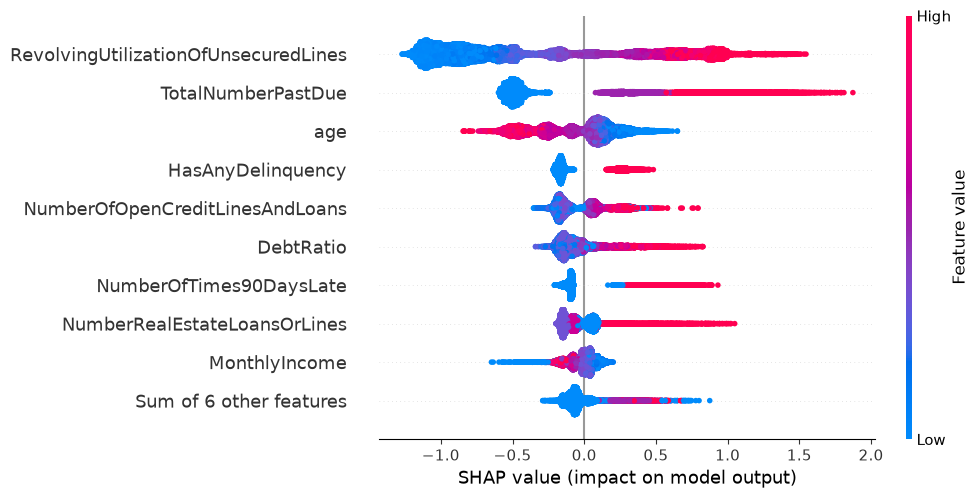

In [26]:
shap.plots.beeswarm(shap_values, max_display=10)

High utilization, delinquencies and debt ratio increase the predicted risk, while higher age decreases it, as seen in the EDA. The number of real estate loans appears to have a non-monotonic effect.

### SHAP bar

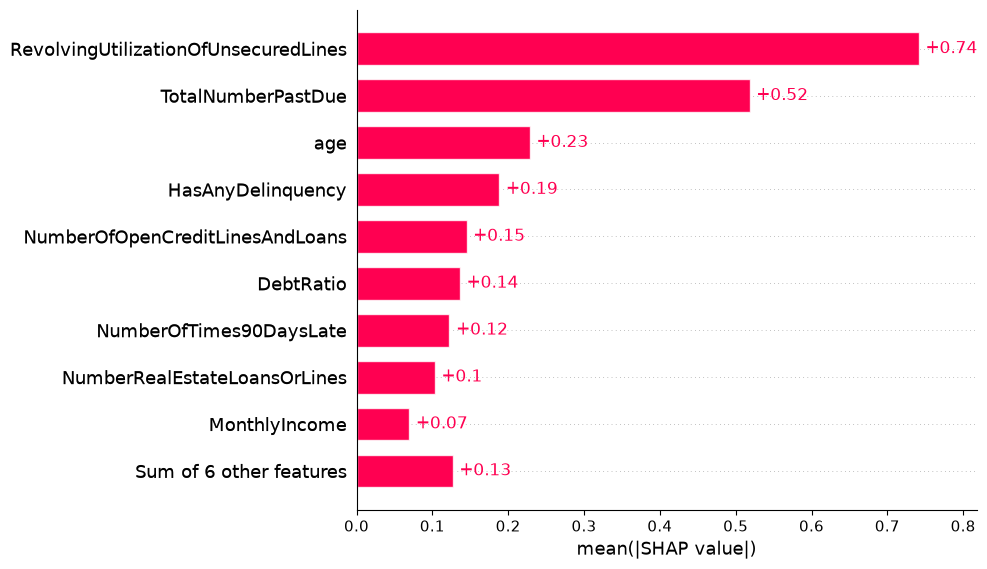

In [27]:
shap.plots.bar(shap_values, max_display=10)


- `RevolvingUtilizationOfUnsecuredLines` and `TotalNumberPastDue` are the most important features, consistent with the EDA.

- The individual delinquency counters show low importance, most likely because `TotalNumberPastDue` captures most of the same information.

### Waterfall for low-risk client

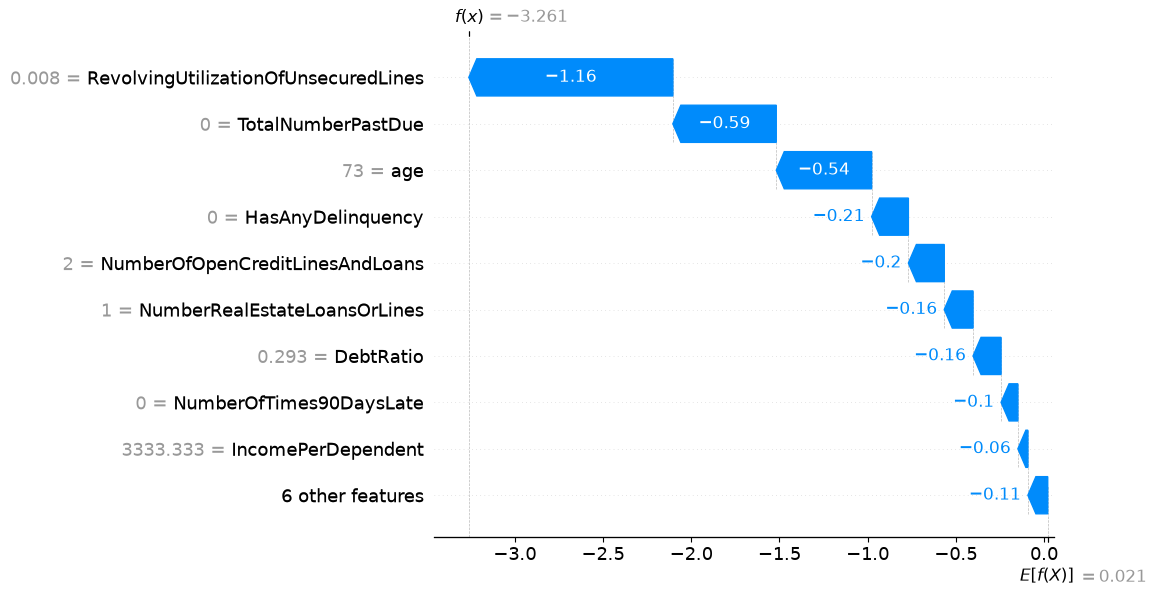

In [28]:
idx_low = np.argmin(y_proba)
shap.plots.waterfall(shap_values[idx_low])

Example of a low-risk client: zero utilization and no delinquencies strongly lower the predicted risk.

### Waterfall for high-risk client

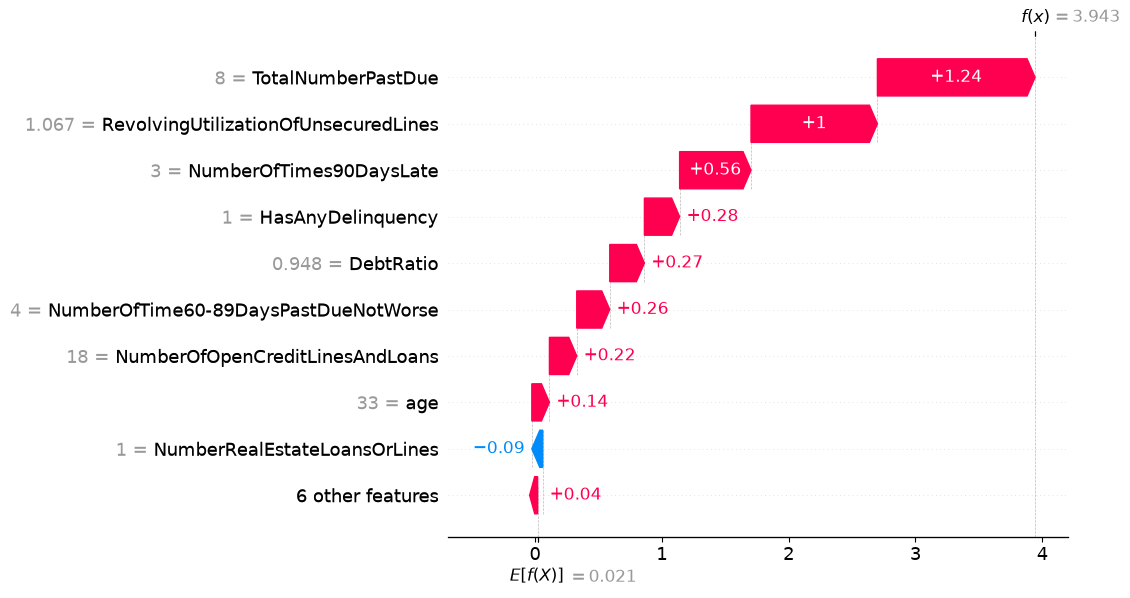

In [29]:
idx_high = np.argmax(y_proba)
shap.plots.waterfall(shap_values[idx_high])

Example of a high-risk client: `TotalNumberPastDue` and `RevolvingUtilizationOfUnsecuredLines` strongly increase the score.

## Conclusions

1. **Final model**. XGBoost with Optuna-tuned parameters is selected. On the test set it achieves AUC 0.870 (Gini 0.740), close to the cross-validation result.

2. **Comparison with the baseline**. XGBoost performs better than logistic regression (CV AUC 0.865 vs 0.857, Gini 0.730 vs 0.714). The gain is small, but XGBoost is better in every fold.

3. **Most important features**. According to SHAP, `RevolvingUtilizationOfUnsecuredLines` and `TotalNumberPastDue` have the strongest impact on predictions, consistent with the EDA. Higher values of both increase the predicted risk.

4. **Decision threshold**. At the threshold of 0.8, the model rejects about 7.5% of applications. 42% of rejected clients are actual defaults (precision), and the model catches 48% of all defaults (recall).

5. **Limitations**.  

   - Predicted probabilities are not calibrated because of `scale_pos_weight`, so they work as a ranking score rather than a direct probability of default.
   - The threshold is chosen by F1, which gives equal weight to wrongly rejected good clients and missed defaults. In practice, the cost of these two errors may differ.
   - The data come from a single public dataset without a time dimension, so the stability of the model over time cannot be checked.
